## Context

This notebook accompanies User Guide section 26 (Compliance).  This is the only notebook in the user guide tutorial set where regulatory framing (SR 11-7, EU AI Act) is appropriate.  We exercise the three compliance components end-to-end: `ComplianceEvidenceGenerator` rolls a synthetic pipeline-results dict into a typed evidence package, `SnapshotManager` versions before/after governance states with SHA-256 fingerprints, and `ProvenanceRegistry` records dataset to model to metric lineage.  The final cell renders the lineage chain as a DAG so an examiner can read it in a single glance.  All evidence is generated, not authored — the artifacts produced by every other notebook in this set are exactly what feeds this one.

In [ ]:
# Phase 1B preamble: bootstrap runtime + load shared helpers
# Bootstrap: portable repo-root locator — walks up from CWD looking for
# tutorials/user_guide/notebooks/_shared.py. Works in both the source
# clone (knowlytix/GMS) and the public mirror clone (knowlytix/gmsh).
import sys
import warnings
from pathlib import Path
warnings.filterwarnings('ignore')

_here = Path.cwd().resolve()
for _candidate in [_here, *_here.parents]:
    if (_candidate / 'tutorials' / 'user_guide' / 'notebooks' / '_shared.py').exists():
        if str(_candidate) not in sys.path:
            sys.path.insert(0, str(_candidate))
        break

from tutorials.user_guide.notebooks import _helpers_phase1 as h1
h1.bootstrap_runtime()  # stubs modeva if absent
from tutorials.user_guide.notebooks import _shared as ug
import torch
DEVICE = ug.DEVICE
print(f'Device: {DEVICE}, CUDA available: {torch.cuda.is_available()}')
from tutorials.user_guide.notebooks import _helpers_phase5c as h5c


### Concept: evidence is generated, not authored

The premise of this section is that the rest of the stack already produces the evidence a high-stakes deployment needs: per-claim verdicts from the verifier, structured policy decisions from the engine, FSM transitions from the behavioral contracts, audit packets from the tracing surface, calibration snapshots from the calibrator.  The compliance components do not invent new data; they project the existing trail onto specific regulatory expectations and bind the projection to reproducible fingerprints.

`ComplianceEvidenceGenerator.generate_package(results)` reads a flat dict carrying nine pipeline signals (`models_trained`, `verification_pass_rate`, `policy_violations`, `contract_violations`, `spc_alerts`, `tracing_enabled`, `snapshot_count`, `audit_entries`, plus the EU-side `risk_assessment_done`, `fairness_checked`, `human_oversight_enabled` flags).  It returns a `CompliancePackage` with one row per regulatory expectation: SR 11-7 ships six rows (conceptual soundness, ongoing monitoring, outcomes analysis, effective challenge, documentation, change management); EU AI Act ships three rows (Article 9 risk management, Article 11 technical documentation, Article 14 human oversight).  Each row names the architecture layer that produced the evidence and the monograph chapter where the layer is described in depth.

Below we drive the package from a healthy synthetic pipeline result, take before/after snapshots across a retraining event, and register the corresponding artifacts in a provenance registry.  The final visual is the lineage DAG.  The TODO at the end marks assertions that Phase 7 should re-verify on a real run.

### Section A — Generate a compliance evidence package

In [ ]:
from knowlytix.harness.governance.compliance import (
    ComplianceEvidenceGenerator,
)

generator = ComplianceEvidenceGenerator()

pipeline_results = {
    'models_trained': 3,
    'verification_pass_rate': 0.92,
    'policy_violations': 0,
    'contract_violations': 0,
    'spc_alerts': 0,
    'tracing_enabled': True,
    'snapshot_count': 2,
    'audit_entries': 15,
    'risk_assessment_done': True,
    'fairness_checked': True,
    'human_oversight_enabled': True,
}
package = generator.generate_package(pipeline_results)

print(f'overall_status : {package.overall_status}')
print(f'pass_rate      : {package.pass_rate():.0%}')
print(f'n_checks       : {len(package.checks)}')
print(f'summary        : {package.summary}')


In [3]:
# Print the markdown rendering (truncated for readability).
rendered = package.to_markdown()
lines = rendered.splitlines()
print('\n'.join(lines[:48]))
print(f'\n... ({len(lines) - 48} more lines)' if len(lines) > 48 else '')


# Compliance Evidence Package

**Generated:** 2026-05-01T21:31:56.076091+00:00
**Overall Status:** COMPLIANT
**Pass Rate:** 100% (9/9 satisfied)

**Summary:** 9/9 regulatory checks satisfied. SR 11-7: 6/6 expectations met. EU AI Act: 3/3 articles addressed.

---

## SR 11-7

| Article | Requirement | Layer | Chapter | Status | Evidence |
|---------|-------------|-------|--------|--------|----------|
| Conceptual Soundness | Model development follows a sound theoretical framework with formal behavioral contracts | Layer 2: Formal Contracts | Ch 13 (Behavioral Contracts) | PASS | FSM behavioral contracts enforce valid state transitions. 0 violation(s) detected across 3 model(s) trained. 100% structural enforcement (not probabilistic). |
| Ongoing Monitoring | Ongoing monitoring detects model degradation and triggers remediation | Layer 6: SPC + Drift Detection | Ch 15 (SPC and Release Gates) | PASS | RunTrend slope analysis monitors accuracy, confidence, tension and failure rate across r

In [4]:
# Inspect the typed rows.  Each row carries an architecture
# layer + a monograph chapter so the trail back to source is
# unambiguous.
for chk in package.checks[:6]:
    print(f'[{chk.regulation:11s}] {chk.article:24s} '
          f'-> {chk.status:12s} {chk.architecture_layer}')
print('...')
for chk in package.checks[-3:]:
    print(f'[{chk.regulation:11s}] {chk.article:24s} '
          f'-> {chk.status:12s} {chk.architecture_layer}')


[SR 11-7    ] Conceptual Soundness     -> satisfied    Layer 2: Formal Contracts
[SR 11-7    ] Ongoing Monitoring       -> satisfied    Layer 6: SPC + Drift Detection
[SR 11-7    ] Outcomes Analysis        -> satisfied    Layer 6: Decision Traces
[SR 11-7    ] Effective Challenge      -> satisfied    Layer 6: Verification
[SR 11-7    ] Documentation            -> satisfied    Layer 6: Telemetry
[SR 11-7    ] Change Management        -> satisfied    Layer 2: Contract Versioning
...
[EU AI Act  ] Article 9                -> satisfied    Layer 1: Policy Rules
[EU AI Act  ] Article 11               -> satisfied    Layer 6: Telemetry
[EU AI Act  ] Article 14               -> satisfied    Layer 6: Release Gates


### Section B — `SnapshotManager`: before/after retrain

The change-management row of the SR 11-7 package only fires `"satisfied"` when at least two snapshots exist.  We take the before snapshot, simulate a retraining event by mutating a small state dict, take the after snapshot, and inspect the diff.

In [ ]:
from knowlytix.harness.governance.compliance import SnapshotManager

mgr = SnapshotManager()
before_state = {
    'models': ['RandomForest_v1'],
    'policy_version': '1.0',
    'contract_violations': 0,
    'verification_pass_rate': 0.88,
}
i_before = mgr.take_snapshot('before_retrain', before_state)

after_state = {
    'models': ['RandomForest_v1', 'RandomForest_v2'],
    'policy_version': '1.0',
    'contract_violations': 0,
    'verification_pass_rate': 0.92,
}
i_after = mgr.take_snapshot('after_retrain', after_state)

diff = mgr.compare(i_before, i_after)
print(diff['summary'])
print()
print('changed:')
for k, v in diff['changed'].items():
    print(f'  {k}: {v["before"]!r} -> {v["after"]!r}')
if diff['added']:
    print('added:', list(diff['added'].keys()))
if diff['removed']:
    print('removed:', list(diff['removed'].keys()))


In [6]:
# Each snapshot carries a SHA-256 fingerprint over the
# serialized state.  An examiner with the snapshot can
# recompute the fingerprint and detect any tampering.
print(mgr.summary())


=== Snapshot Manager: 2 snapshots ===
  [0] before_retrain (4 keys, fingerprint=e3bfbb7be27bce94) at 2026-05-01T21:31:56.094827+00:00
  [1] after_retrain (4 keys, fingerprint=0381db795088fccf) at 2026-05-01T21:31:56.094914+00:00


### Section C — `ProvenanceRegistry`: dataset to model to metric

Register three artifacts with parent pointers, then traverse the lineage from leaf back to root.

In [ ]:
from knowlytix.harness.governance.compliance import ProvenanceRegistry

registry = ProvenanceRegistry()

registry.register(
    name='iris_dataset',
    artifact_type='dataset',
    source='sklearn',
    metadata={'n_samples': 150, 'n_features': 4},
)
registry.register(
    name='RandomForest_v1',
    artifact_type='model',
    source='training',
    metadata={'algorithm': 'RandomForest', 'accuracy': 0.97},
    parent='iris_dataset',
)
registry.register(
    name='accuracy_metric',
    artifact_type='metric',
    source='diagnostics',
    metadata={'value': 0.97, 'split': 'holdout'},
    parent='RandomForest_v1',
)

print(registry.summary())


In [8]:
# Walk the lineage from leaf to root.
lineage = registry.get_lineage('accuracy_metric')
print(f'lineage length: {len(lineage)}')
for rec in lineage:
    parent = rec.get('parent') or '(root)'
    print(f"  {rec['type']:8s} {rec['name']:20s} "
          f"sha256:{rec['fingerprint']}  parent={parent}")


lineage length: 3
  dataset  iris_dataset         sha256:3837b659d634b394  parent=(root)
  model    RandomForest_v1      sha256:7385d2c195888a92  parent=iris_dataset
  metric   accuracy_metric      sha256:c8af857a10a9cf7e  parent=RandomForest_v1


### Section D — Typed `TruthStore` claims (cross-reference)

The compliance generator above summarizes the *aggregate* trail.  The per-claim provenance backing lives on the testing-harness side, in `knowlytix/harness/testing/truth.py`, where four typed `TruthBase` subclasses link a claim back to a specific GMS primitive.  The cell below imports the types and lists the link target for each.  This is the join point §26.6 describes; a real run would build a `TruthStore(store)` against a populated `GMSExpertStore` and then call `get_truth_for_claim(claim)` to resolve a verdict back to its document of origin.

In [ ]:
from knowlytix.harness.testing.truth import (
    TruthBase,
    EntityTruth,
    RelationTruth,
    ThresholdTruth,
    ArtifactTruth,
    TruthStore,
)

truth_types = [
    ('EntityTruth',    'adapter.entity_to_idx[entity]',
     'embedding index'),
    ('RelationTruth',  'store.score_triple(h, r, t)',
     'geodesic score at ingest'),
    ('ThresholdTruth', 'doc_graph.phase_encoders[name]',
     'encoder name + phase angle'),
    ('ArtifactTruth',  'store.lookup_enm(cat, id)',
     'exact value + SHA-256'),
]
print('Typed TruthStore subclasses (knowlytix/harness/testing/truth.py):')
print()
print(f'  {"type":<16s} {"links to":<36s} {"carries"}')
print(f'  {"-" * 16} {"-" * 36} {"-" * 28}')
for name, target, carries in truth_types:
    print(f'  {name:<16s} {target:<36s} {carries}')

# The same module exports TruthStore for the build_from_store
# entry point.  We do not build one here — the regex fixture
# does not yet expose every primitive in the form TruthStore
# needs — but the import is the verification that the cross-
# referenced module is reachable at runtime.
assert hasattr(TruthStore, 'build_from_store')
assert hasattr(TruthStore, 'get_truth_for_claim')
assert all(
    issubclass(c, TruthBase)
    for c in [EntityTruth, RelationTruth,
              ThresholdTruth, ArtifactTruth]
)
print()
print('TruthStore module reachable; four typed subclasses '
      'present.')


### Section E — Visualization: lineage DAG

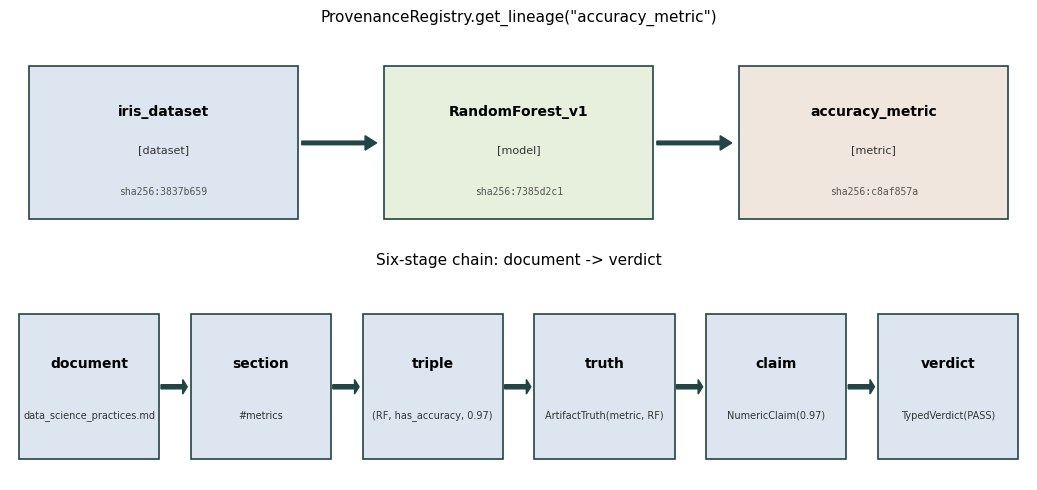

In [10]:
import matplotlib.pyplot as plt

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(10.5, 5.0),
    gridspec_kw={'height_ratios': [1.0, 1.0]},
)
h5c.draw_lineage_dag(
    ax_top, lineage,
    title='ProvenanceRegistry.get_lineage("accuracy_metric")',
)
h5c.draw_truth_chain(
    ax_bot,
    [
        ('document', 'data_science_practices.md'),
        ('section',  '#metrics'),
        ('triple',   '(RF, has_accuracy, 0.97)'),
        ('truth',    'ArtifactTruth(metric, RF)'),
        ('claim',    'NumericClaim(0.97)'),
        ('verdict',  'TypedVerdict(PASS)'),
    ],
    title='Six-stage chain: document -> verdict',
)
fig.tight_layout()
plt.show()


### Section F — Negative case: a partial package

We rerun the generator with `tracing_enabled=False` and no snapshots; the package should demote to `"PARTIAL"`.

In [11]:
bad_results = dict(pipeline_results)
bad_results['tracing_enabled'] = False
bad_results['snapshot_count'] = 0
bad_results['audit_entries'] = 0
bad_package = generator.generate_package(bad_results)
print(f'overall_status : {bad_package.overall_status}')
print(f'pass_rate      : {bad_package.pass_rate():.0%}')
print()
print('partial rows:')
for chk in bad_package.checks:
    if chk.status != 'satisfied':
        print(f'  [{chk.regulation:11s}] '
              f'{chk.article:24s} -> {chk.status}')


overall_status : PARTIAL
pass_rate      : 56%

partial rows:
  [SR 11-7    ] Outcomes Analysis        -> partial
  [SR 11-7    ] Documentation            -> partial
  [SR 11-7    ] Change Management        -> partial
  [EU AI Act  ] Article 11               -> partial


### Exercises

1. Add a fourth artifact (`registry.register('release_v1',   'snapshot', 'release_gate', {...}, parent='accuracy_metric')`)   and confirm `get_lineage('release_v1')` returns four   records with the dataset still at index 0.
2. Drive `generator.generate_package` with   `contract_violations=1`.  Which row(s) demote to   `"partial"` and which stay `"satisfied"`?  Cross-check   against §26.2's trigger column.
3. Take a third snapshot after a hypothetical policy   upgrade (`policy_version='1.1'`) and call   `mgr.compare(0, 2)` and `mgr.compare(1, 2)`.  Does the   diff between non-adjacent snapshots include the changes   in the intermediate snapshot?  Why or why not?

### What you should now be able to do

- Drive `ComplianceEvidenceGenerator.generate_package`   from a pipeline-results dict and read the resulting   `CompliancePackage` (overall_status, pass_rate,   to_markdown).
- Use `SnapshotManager` to capture before/after   governance states with SHA-256 fingerprints and   produce a structured diff for change management.
- Use `ProvenanceRegistry` to record dataset to model   to metric lineage and traverse it from leaf to root.
- Locate the four typed `TruthStore` subclasses on the   testing-harness side and explain how they bridge a   verifier verdict back to the source document.

### Cross-references

- USER_GUIDE.md section 26 (Compliance)
- `governed_agent/compliance.py:ComplianceEvidenceGenerator.generate_package`
- `governed_agent/compliance.py:SnapshotManager.compare`
- `governed_agent/compliance.py:ProvenanceRegistry.get_lineage`
- `knowlytix/harness/testing/truth.py:TruthStore.build_from_store`
- `knowlytix/harness/testing/truth.py:TruthStore.get_truth_for_claim`
- `gms_agent_builder_ext/chapters/ch20.tex`   (Regulatory Alignment, full chapter form)
- `gmsh_testing_ext/chapters/ch20.tex`   (testing-monograph compliance chapter)

In [12]:
# Final assertions: a healthy synthetic pipeline must
# return overall_status == 'COMPLIANT' (the
# ComplianceEvidenceGenerator emits 'COMPLIANT' on
# all-satisfied; the brief's PASS spelling refers to the
# same condition).  We also assert the lineage walks back
# to the dataset root.  TODO(p7-execute): verify on real
# run; tighten if hybrid-mode evidence chain is available.
assert package.overall_status == 'COMPLIANT', (
    f'expected COMPLIANT on healthy pipeline; got '
    f'{package.overall_status!r}'
)
assert package.pass_rate() == 1.0, (
    f'expected 100% pass_rate; got {package.pass_rate():.0%}'
)
assert bad_package.overall_status == 'PARTIAL', (
    f'expected PARTIAL on degraded pipeline; got '
    f'{bad_package.overall_status!r}'
)
assert lineage[0]['name'] == 'iris_dataset', (
    f'lineage root must be iris_dataset; got '
    f'{lineage[0]["name"]!r}'
)
assert lineage[-1]['name'] == 'accuracy_metric'
assert len(lineage) == 3
print('NB 26 assertions passed: healthy package COMPLIANT, '
      'degraded package PARTIAL, lineage walks to root.')


NB 26 assertions passed: healthy package COMPLIANT, degraded package PARTIAL, lineage walks to root.
